# Spotify Analytics — Cassandra + PySpark MLlib

Read songs from Cassandra, calculate a custom popularity score, rank artists/songs, train regression models, recommend tracks and plot results.

**Requirements:** Cassandra running locally; keyspace `spotify`, table `spotify_youtube_full`; Java installed and configured for PySpark.

The score is custom, not Spotify's official score. Each code cell has a short explanation.

## 1. Install dependencies

Install PySpark, the Cassandra driver and plotting/data libraries. Start Cassandra and run the data-ingestion notebook first.

**Cell explanation:** Install the libraries required by the notebook.


In [1]:
%pip install pyspark==3.5.8 cassandra-driver matplotlib pandas numpy


Note: you may need to restart the kernel to use updated packages.


## 2. Imports and Spark setup

**Explanation:** Set Python worker settings and check the installed versions.

In [2]:
import os, sys, pyspark

os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
# Windows: Hadoop needs winutils to write files (model save, etc.).
os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
os.environ["PATH"] = os.path.join(os.environ["HADOOP_HOME"], "bin") + os.pathsep + os.environ["PATH"]

print("Python:", sys.version.split()[0], "| PySpark:", pyspark.__version__)
print("JAVA_HOME:", os.environ.get("JAVA_HOME", "Using system Java"))

Python: 3.11.15 | PySpark: 3.5.8
JAVA_HOME: C:\Program Files\Java\jdk-17.0.21.0.2


**Explanation:** Import Spark/Cassandra tools, define columns and start local Spark.

In [3]:
from cassandra.cluster import Cluster
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

KEYSPACE, TABLE = "spotify", "spotify_youtube_full"
AUDIO = [
    "danceability", "energy", "key", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration_ms"
]
ENGAGEMENT = ["stream", "views", "likes", "comments"]

# Use a small local Spark configuration for a 19k-row dataset.
spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("SpotifyAnalytics")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.hadoop.hadoop.home.dir", os.environ["HADOOP_HOME"])
    .config("spark.sql.execution.arrow.pyspark.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Spark started:", spark.version)


Spark started: 3.5.8


## 3. Read Cassandra data into Spark

**Explanation:** Read the Cassandra table and create a Spark DataFrame.

In [4]:
# Connect to Cassandra once and load the source table.
cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect(KEYSPACE)

from pyspark.sql.types import (
    StructType, StructField, StringType, LongType, DoubleType,
    BooleanType, TimestampType, DateType, BinaryType,
)

# Map Cassandra column types to Spark types so schema inference never fails
# on columns whose first sampled value is null.
CQL_TO_SPARK = {
    "text": StringType(), "ascii": StringType(), "varchar": StringType(),
    "int": LongType(), "bigint": LongType(), "smallint": LongType(),
    "tinyint": LongType(), "varint": LongType(),
    "double": DoubleType(), "float": DoubleType(),
    "boolean": BooleanType(),
    "timestamp": TimestampType(), "date": DateType(),
    "uuid": StringType(), "timeuuid": StringType(),
    "blob": BinaryType(),
}

table_meta = session.cluster.metadata.keyspaces[KEYSPACE].tables[TABLE]
schema = StructType([
    StructField(col.name, CQL_TO_SPARK.get(str(col.cql_type), StringType()), True)
    for col in table_meta.columns.values()
])

rows = session.execute(f"SELECT * FROM {TABLE}")
records = [row._asdict() for row in rows]

print("Records loaded:", len(records))
if not records:
    raise ValueError(
        f"No rows found in {KEYSPACE}.{TABLE}. Check Cassandra is running "
        "and the table contains data."
    )

print("First record keys:", list(records[0].keys()))

# Build the Spark DataFrame once with an explicit schema.
df = spark.createDataFrame(records, schema=schema)
print("Columns:", len(df.columns))
df.printSchema()
# Test whether Spark can execute a basic action
print("Rows:", df.count())

# Display using a fresh DataFrame
df.limit(5).toPandas()


Records loaded: 19170
First record keys: ['row_id', 'acousticness', 'album', 'album_type', 'artist', 'channel', 'comments', 'danceability', 'description', 'duration_ms', 'energy', 'instrumentalness', 'key', 'licensed', 'likes', 'liveness', 'loudness', 'official_video', 'popularity_score', 'score_version', 'speechiness', 'stream', 'tempo', 'title', 'track', 'uri', 'url_spotify', 'url_youtube', 'valence', 'views']


Columns: 30
root
 |-- row_id: long (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- album: string (nullable = true)
 |-- album_type: string (nullable = true)
 |-- artist: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- comments: double (nullable = true)
 |-- danceability: double (nullable = true)
 |-- description: string (nullable = true)
 |-- duration_ms: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- key: double (nullable = true)
 |-- licensed: boolean (nullable = true)
 |-- likes: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- loudness: double (nullable = true)
 |-- official_video: boolean (nullable = true)
 |-- popularity_score: double (nullable = true)
 |-- score_version: string (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- stream: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- title: string (nullable = true)
 |-

Rows: 19170


,row_id,acousticness,album,album_type,artist,channel,comments,danceability,description,duration_ms,...,speechiness,stream,tempo,title,track,uri,url_spotify,url_youtube,valence,views
0,4317,0.796,Tuesday Night Music Club,album,Sheryl Crow,MAINSTREAM TOP MUSIC,102.0,0.580,Strong Enough · Sheryl Crow Tuesday Night Musi...,189827.0,...,0.0317,51767995.0,154.595,SHERYL CROW - STRONG ENOUGH (OFFICIAL MUSIC V...,Strong Enough,spotify:track:25IRjWUZ60n7KXxcB4DiX9,https://open.spotify.com/artist/4TKTii6gnOnUXQ...,https://www.youtube.com/watch?v=7CCWMMEN1Vc,0.583,97038.0
1,3372,0.776,At Last!,album,Etta James,Classic Mood Experience,185.0,0.486,Classic Mood Experience The best masterpieces ...,178467.0,...,0.0309,17660226.0,64.033,Etta James - Trust In Me,Trust In Me,spotify:track:5Zu9mG353GB3p26t7M5AmR,https://open.spotify.com/artist/0iOVhN3tnSvgDb...,https://www.youtube.com/watch?v=rwWJgHEcMrs,0.500,985595.0
2,14340,0.664,Mon Laferte (Vol. 1),album,Mon Laferte,MonLaferteVEVO,14805.0,0.393,Producido y Dirigido por Carolina Dagach\n\nSt...,241880.0,...,0.0269,129999337.0,175.548,Mon Laferte - Amor Completo,Amor Completo,spotify:track:00kIWJu9IHiQ6i0qJAU0Z9,https://open.spotify.com/artist/4boI7bJtmB1L3b...,https://www.youtube.com/watch?v=PQlG1gznMBE,0.346,170138206.0
3,18417,0.301,Nie mehr gehen,single,Apache 207,Apache 207,3092.0,0.704,Vorverkaufsstart - Dienstag 25.10 / 16:00 auf ...,195925.0,...,0.0425,9903711.0,139.924,DANKESCHÖN (Nie mehr gehen),Nie mehr gehen,spotify:track:3iBU3w9MbrqFdB9mOa2JeK,https://open.spotify.com/artist/1qQLhymHXFPtP5...,https://www.youtube.com/watch?v=UaOdBXw9SY0,0.240,2293294.0
4,1584,0.733,Star Wars: The Phantom Menace (Original Motion...,album,London Symphony Orchestra,FilmTrailersChannel,285.0,0.471,Duel Of Fates Music Video\n\nConducted And Wri...,254347.0,...,0.0410,91702045.0,79.986,Star Wars The Phantom Menace Music Video - [Du...,Duel of the Fates,spotify:track:1ghlpxVfPbFH2jenrv9vVw,https://open.spotify.com/artist/5yxyJsFanEAuwS...,https://www.youtube.com/watch?v=nIgZS5tieeE,0.282,259284.0


## 4. Clean numeric columns

Cast audio and engagement fields to numeric values; invalid and infinite values become null.

**Explanation:** Validate required fields and clean numeric columns.

In [5]:
# Identify the expected columns present in the Cassandra table.
audio_cols = [c for c in AUDIO if c in df.columns]
engagement_cols = [c for c in ENGAGEMENT if c in df.columns]

if not audio_cols:
    raise ValueError(f"No audio feature columns found. Available columns: {df.columns}")
if not engagement_cols:
    raise ValueError(f"No engagement columns found. Available columns: {df.columns}")
if not {"artist", "track"}.issubset(df.columns):
    raise ValueError("Dataset must contain both 'artist' and 'track' columns.")

# Cast expected numeric features to double. Invalid strings become null.
for c in audio_cols + engagement_cols:
    df = df.withColumn(c, F.col(c).cast(DoubleType()))

# Replace NaN and +/- infinity with null using explicit numeric predicates.
for c in audio_cols + engagement_cols:
    df = df.withColumn(
        c,
        F.when(
            F.isnan(F.col(c)) |
            (F.col(c) == F.lit(float("inf"))) |
            (F.col(c) == F.lit(float("-inf"))),
            F.lit(None).cast("double")
        ).otherwise(F.col(c))
    )

print("Audio columns:", audio_cols)
print("Engagement columns:", engagement_cols)
df.select("artist", "track", *audio_cols[:3], *engagement_cols).show(5, truncate=True)


Audio columns: ['danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
Engagement columns: ['stream', 'views', 'likes', 'comments']


+--------------------+-----------------+------------+------+----+------------+------------+--------+--------+
|              artist|            track|danceability|energy| key|      stream|       views|   likes|comments|
+--------------------+-----------------+------------+------+----+------------+------------+--------+--------+
|         Sheryl Crow|    Strong Enough|        0.58| 0.265| 2.0| 5.1767995E7|     97038.0|  1798.0|   102.0|
|          Etta James|      Trust In Me|       0.486| 0.377|10.0| 1.7660226E7|    985595.0|  7942.0|   185.0|
|         Mon Laferte|    Amor Completo|       0.393| 0.418| 4.0|1.29999337E8|1.70138206E8|677915.0| 14805.0|
|          Apache 207|   Nie mehr gehen|       0.704| 0.318| 0.0|   9903711.0|   2293294.0| 58206.0|  3092.0|
|London Symphony O...|Duel of the Fates|       0.471| 0.411| 2.0| 9.1702045E7|    259284.0|  4134.0|   285.0|
+--------------------+-----------------+------------+------+----+------------+------------+--------+--------+
only showi

## 5. Custom popularity score (0–100)

Weights: streams 40%, views 25%, likes 10%, comments 5%, audio features 20%. Engagement values use `log1p` plus min-max normalization; audio uses min-max normalization. Missing components are excluded and remaining weights are rescaled. This is not Spotify's official formula.

Scores are versioned as `v2_audio_engagement`: old/unmarked scores are migrated once, while current-version scores are preserved on later runs.

### 5A. Score weights and migration check

**Explanation:** Set weights and check which scores need migration.

In [6]:
# Score weights and version
W_ENGAGEMENT = {"stream": 0.40, "views": 0.25, "likes": 0.10, "comments": 0.05}
AUDIO_SCORE_COLS = ["danceability", "energy", "valence", "loudness"]
W_AUDIO, SCORE_VERSION = 0.20, "v2_audio_engagement"

assert abs(sum(W_ENGAGEMENT.values()) + W_AUDIO - 1) < 1e-9
print("Weights total 100%; score version:", SCORE_VERSION)

def ensure_column(frame, name, cassandra_type, spark_type):
    if name in frame.columns:
        return frame
    session.execute(f"ALTER TABLE {TABLE} ADD {name} {cassandra_type}")
    return frame.withColumn(name, F.lit(None).cast(spark_type))

df = ensure_column(df, "popularity_score", "double", "double")
df = ensure_column(df, "score_version", "text", "string")

total_rows = df.count()
is_current = F.col("popularity_score").isNotNull() & (F.col("score_version") == SCORE_VERSION)
current_rows = df.where(is_current).count()
CALCULATE_SCORE = current_rows < total_rows

print(f"Rows: {total_rows}; current v2 scores: {current_rows}")
print("Action:", "calculate/migrate old or missing scores" if CALCULATE_SCORE else "skip; scores already current")


Weights total 100%; score version: v2_audio_engagement


Rows: 19170; current v2 scores: 19170
Action: skip; scores already current


### 5B. Popularity score formula

Normalize engagement and audio features, combine the available components, and return a score from 0 to 100.

**Explanation:** Calculate the weighted 0–100 popularity score.

In [7]:
def build_popularity_scores(source):
    """Calculate 0–100 score; missing components are excluded and weights rebalanced."""
    required = set(W_ENGAGEMENT) | set(AUDIO_SCORE_COLS)
    missing = required - set(source.columns)
    if missing:
        raise ValueError(f"Missing score columns: {sorted(missing)}")

    # Log-transform engagement counts; audio values are normalized as-is.
    def logged(c):
        return F.log1p(F.greatest(F.col(c), F.lit(0.0)))

    stats_exprs = []
    for c in W_ENGAGEMENT:
        stats_exprs += [F.min(logged(c)).alias(f"min_{c}"), F.max(logged(c)).alias(f"max_{c}")]
    for c in AUDIO_SCORE_COLS:
        stats_exprs += [F.min(c).alias(f"min_{c}"), F.max(c).alias(f"max_{c}")]
    stats = source.select(*stats_exprs).first()

    def norm(value, low, high):
        if low is None or high is None:
            return F.lit(None).cast("double")
        if high == low:
            return F.when(value.isNull(), None).otherwise(F.lit(0.0))
        return (value - F.lit(low)) / F.lit(high - low)

    expressions = []
    for c in W_ENGAGEMENT:
        expressions.append(norm(logged(c), stats[f"min_{c}"], stats[f"max_{c}"]).alias(f"_n_{c}"))
    for c in AUDIO_SCORE_COLS:
        expressions.append(norm(F.col(c), stats[f"min_{c}"], stats[f"max_{c}"]).alias(f"_n_{c}"))
    work = source.select("*", *expressions)

    # Audio contribution is the mean of whichever audio features are present.
    audio_cols = [f"_n_{c}" for c in AUDIO_SCORE_COLS]
    audio_count = sum(F.when(F.col(c).isNotNull(), 1).otherwise(0) for c in audio_cols)
    audio_mean = sum(F.coalesce(F.col(c), F.lit(0.0)) for c in audio_cols) / F.greatest(audio_count, F.lit(1))
    work = work.withColumn("_audio", F.when(audio_count > 0, audio_mean))

    # Rebalance weights over the components available for each row.
    numerator, denominator = F.lit(0.0), F.lit(0.0)
    for c, weight in W_ENGAGEMENT.items():
        value = F.col(f"_n_{c}")
        numerator += F.coalesce(value * weight, F.lit(0.0))
        denominator += F.when(value.isNotNull(), F.lit(weight)).otherwise(F.lit(0.0))
    numerator += F.coalesce(F.col("_audio") * W_AUDIO, F.lit(0.0))
    denominator += F.when(F.col("_audio").isNotNull(), F.lit(W_AUDIO)).otherwise(F.lit(0.0))

    work = work.withColumn(
        "_new_score",
        F.when(denominator > 0, F.round(100 * numerator / denominator, 2))
    )
    was_current = F.col("popularity_score").isNotNull() & (F.col("score_version") == SCORE_VERSION)
    work = work.withColumn("_needs_write", ~was_current & F.col("_new_score").isNotNull())
    work = work.withColumn(
        "popularity_score",
        F.when(was_current, F.col("popularity_score")).otherwise(F.col("_new_score"))
    ).withColumn(
        "score_version",
        F.when(was_current | F.col("_needs_write"), SCORE_VERSION).otherwise(F.col("score_version"))
    )

    helper_cols = [f"_n_{c}" for c in W_ENGAGEMENT] + audio_cols + ["_audio", "_new_score"]
    work = work.drop(*helper_cols)
    low, high = work.select(F.min("popularity_score"), F.max("popularity_score")).first()
    assert low is None or low >= 0, f"Score below 0: {low}"
    assert high is None or high <= 100, f"Score above 100: {high}"
    return work


### 5C. Calculate or skip

**Explanation:** Recalculate only old or missing-version scores.

In [8]:
if CALCULATE_SCORE:
    df = build_popularity_scores(df)
else:
    df = df.withColumn("_needs_write", F.lit(False))

df.select("artist", "track", "popularity_score", "score_version").show(10, truncate=False)


+-------------------------+----------------------------------+----------------+-------------------+
|artist                   |track                             |popularity_score|score_version      |
+-------------------------+----------------------------------+----------------+-------------------+
|Sheryl Crow              |Strong Enough                     |53.91           |v2_audio_engagement|
|Etta James               |Trust In Me                       |55.19           |v2_audio_engagement|
|Mon Laferte              |Amor Completo                     |70.4            |v2_audio_engagement|
|Apache 207               |Nie mehr gehen                    |55.88           |v2_audio_engagement|
|London Symphony Orchestra|Duel of the Fates                 |56.29           |v2_audio_engagement|
|Soprano                  |En feu                            |73.32           |v2_audio_engagement|
|Jaden                    |On My Own                         |65.83           |v2_audio_engagement|


## 6. Save scores to Cassandra

Use all partition and clustering key columns in the update. Current-version rows are left untouched.

**Explanation:** Save changed scores using the complete Cassandra primary key.

In [9]:
from math import isclose

table_meta = session.cluster.metadata.keyspaces[KEYSPACE].tables[TABLE]
key_cols = (
    [c.name for c in table_meta.partition_key]
    + [c.name for c in table_meta.clustering_key]
)

where_clause = " AND ".join(f"{c} = ?" for c in key_cols)

select_existing = session.prepare(
    f"SELECT popularity_score, score_version FROM {TABLE} WHERE {where_clause}"
)

update_score = session.prepare(
    f"UPDATE {TABLE} SET popularity_score = ?, score_version = ? "
    f"WHERE {where_clause}"
)

rows_to_check = (
    df.where(F.col("popularity_score").isNotNull())
      .select("popularity_score", *key_cols)
      .toLocalIterator()
)

updated = skipped = 0

for row in rows_to_check:
    new_score = float(row["popularity_score"])
    key_values = [row[c] for c in key_cols]

    result = session.execute(select_existing, key_values)
    existing = result.one()

    if existing and existing.popularity_score is not None:
        old_score = float(existing.popularity_score)

        if existing.score_version == SCORE_VERSION and isclose(
            old_score, new_score, rel_tol=1e-9, abs_tol=1e-9
        ):
            skipped += 1
            continue

    session.execute(
        update_score,
        [new_score, SCORE_VERSION] + key_values
    )
    updated += 1

print(f"Updated: {updated} | Skipped (same score): {skipped}")

Updated: 0 | Skipped (same score): 19170


## 7. Artist mapping

Sum streams for each artist and show the top 10 artists.

**Explanation:** Aggregate streams to rank artists.

In [10]:
if "stream" not in df.columns:
    raise ValueError("Artist ranking requires stream column.")

artist_streams = (
    df.where(F.col("artist").isNotNull() & F.col("stream").isNotNull())
      .groupBy("artist")
      .agg(F.sum("stream").alias("total_streams"))
      .orderBy(F.desc("total_streams"))
)
top10_artists = artist_streams.limit(10)
top10_artists.show(truncate=False)

+---------------+---------------+
|artist         |total_streams  |
+---------------+---------------+
|Post Malone    |1.5251263853E10|
|Ed Sheeran     |1.4394881557E10|
|Dua Lipa       |1.3408076274E10|
|The Weeknd     |1.2464283476E10|
|XXXTENTACION   |1.2011910355E10|
|Imagine Dragons|1.1858310928E10|
|Coldplay       |1.1778478236E10|
|Khalid         |1.1386839915E10|
|Ariana Grande  |1.0857411888E10|
|Billie Eilish  |1.0747172641E10|
+---------------+---------------+



## 8. Top five songs per artist

Rank songs by summed streams within each of the top 10 artists.

**Explanation:** Show each top artist's five highest-streamed songs.

In [11]:
from pyspark.sql.window import Window

song_streams = (
    df.where(F.col("artist").isNotNull() & F.col("track").isNotNull() & F.col("stream").isNotNull())
      .groupBy("artist", "track")
      .agg(F.sum("stream").alias("total_streams"))
)
w = Window.partitionBy("artist").orderBy(F.desc("total_streams"))
ranked_songs = song_streams.withColumn("rank", F.row_number().over(w))
top5_songs = (
    ranked_songs.join(top10_artists.select("artist"), "artist")
                .where(F.col("rank") <= 5)
                .orderBy("artist", "rank")
)
top5_songs.show(100, truncate=False)

+---------------+-----------------------------------------------------------+-------------+----+
|artist         |track                                                      |total_streams|rank|
+---------------+-----------------------------------------------------------+-------------+----+
|Ariana Grande  |7 rings                                                    |1.89570637E9 |1   |
|Ariana Grande  |thank u, next                                              |1.634130431E9|2   |
|Ariana Grande  |positions                                                  |1.144347767E9|3   |
|Ariana Grande  |One Last Time                                              |1.090948668E9|4   |
|Ariana Grande  |Save Your Tears (Remix) (with Ariana Grande) - Bonus Track |1.025392875E9|5   |
|Billie Eilish  |bad guy                                                    |2.203014126E9|1   |
|Billie Eilish  |lovely (with Khalid)                                       |2.110573779E9|2   |
|Billie Eilish  |when the part

## 9. Train PySpark MLlib models

Predict the custom score using available audio features plus `log1p(stream)`. Exclude views, likes and comments from inputs because they directly contribute to the target.

### 9A. Prepare the ML dataset

**Explanation:** Prepare the ML target and input features.

In [12]:
# Use audio features plus log1p(stream); views, likes and comments stay excluded.
if "stream" not in df.columns:
    raise ValueError("The ML model requires the stream column.")

feature_cols = list(audio_cols) + ["log1p_stream"]
ml_df = df.select(*audio_cols, "stream", "popularity_score")

for c in audio_cols + ["stream", "popularity_score"]:
    ml_df = ml_df.withColumn(c, F.col(c).cast("double"))

ml_df = ml_df.withColumn(
    "log1p_stream",
    F.when(F.col("stream").isNotNull(), F.log1p(F.greatest("stream", F.lit(0.0))))
)
# Invalid feature values become null; the Imputer handles them.
for c in feature_cols:
    ml_df = ml_df.withColumn(
        c, F.when(F.col(c).isNull() | F.isnan(c) |
                  (F.abs(F.col(c)) == float("inf")), None).otherwise(F.col(c))
    )

ml_df = ml_df.where(F.col("popularity_score").isNotNull() & ~F.isnan("popularity_score"))
feature_cols = [c for c in feature_cols if ml_df.where(F.col(c).isNotNull()).limit(1).count()]
if not feature_cols or not ml_df.limit(1).count():
    raise ValueError("Not enough valid rows/features for model training.")

train, test = ml_df.randomSplit([0.8, 0.2], seed=42)
print("Features:", feature_cols)
print("Excluded target components:", ["views", "likes", "comments"])
print("Training rows:", train.count(), "| Test rows:", test.count())


Features: ['danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'log1p_stream']
Excluded target components: ['views', 'likes', 'comments']


Training rows: 15454 | Test rows: 3716


### 9B. Train and compare models

Compare Linear Regression, Random Forest and Gradient-Boosted Trees using R², MAE and RMSE on the same 80/20 split.

**Explanation:** Train and compare three regression models.

In [13]:
# Compare three regression models on the same held-out test set.
imputed = [c + "_imp" for c in feature_cols]

def stages(scale=False):
    result = [Imputer(inputCols=feature_cols, outputCols=imputed, strategy="median"),
              VectorAssembler(inputCols=imputed, outputCol="raw_features")]
    if scale:
        result.append(StandardScaler(inputCol="raw_features", outputCol="features"))
    else:
        result.append(VectorAssembler(inputCols=imputed, outputCol="features"))
    return result

pipelines = {
    "Linear Regression": Pipeline(stages=stages(True) + [
        LinearRegression(featuresCol="features", labelCol="popularity_score")]),
    "Random Forest": Pipeline(stages=stages() + [
        RandomForestRegressor(featuresCol="features", labelCol="popularity_score",
                              numTrees=100, seed=42)]),
    "Gradient Boosting": Pipeline(stages=stages() + [
        GBTRegressor(featuresCol="features", labelCol="popularity_score",
                     maxIter=100, seed=42)])
}

evaluators = {
    metric: RegressionEvaluator(labelCol="popularity_score",
                                predictionCol="prediction", metricName=metric)
    for metric in ["r2", "mae", "rmse"]
}
trained, metrics = {}, []
for name, pipeline in pipelines.items():
    model = pipeline.fit(train)
    pred = model.transform(test).cache()
    scores = [evaluators[m].evaluate(pred) for m in ["r2", "mae", "rmse"]]
    pred.unpersist()
    trained[name] = model
    metrics.append((name, *map(float, scores)))
    print(f"{name}: R²={scores[0]:.4f}, MAE={scores[1]:.4f}, RMSE={scores[2]:.4f}")

results_df = spark.createDataFrame(metrics, ["Model", "R2", "MAE", "RMSE"]).orderBy("MAE")
results_df.show(truncate=False)
best_name = min(metrics, key=lambda row: row[2])[0]
best_model = trained[best_name]
print("Best model by MAE:", best_name)


Linear Regression: R²=0.8242, MAE=3.1287, RMSE=4.2694


Random Forest: R²=0.7296, MAE=4.0110, RMSE=5.2945


Gradient Boosting: R²=0.8208, MAE=3.1446, RMSE=4.3098


+-----------------+------------------+------------------+------------------+
|Model            |R2                |MAE               |RMSE              |
+-----------------+------------------+------------------+------------------+
|Linear Regression|0.8241874619115858|3.1287155195056457|4.26938924162258  |
|Gradient Boosting|0.820842694298204 |3.1446496251093237|4.309809666245548 |
|Random Forest    |0.7296261991333997|4.010956795572945 |5.2944778135552015|
+-----------------+------------------+------------------+------------------+

Best model by MAE: Linear Regression


**Explanation:** Evaluate the best model on test data.

In [14]:
from pyspark.sql import functions as F
from pyspark.ml.evaluation import RegressionEvaluator

# Generate predictions using the best model
predictions = best_model.transform(test).cache()

# Evaluate model
evaluator = RegressionEvaluator(
    labelCol="popularity_score",
    predictionCol="prediction"
)

mae = evaluator.setMetricName("mae").evaluate(predictions)
rmse = evaluator.setMetricName("rmse").evaluate(predictions)
r2 = evaluator.setMetricName("r2").evaluate(predictions)

print("Best Model:", best_name)
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

predictions.select(
    "popularity_score", "prediction"
).show(10, truncate=False)

Best Model: Linear Regression
MAE  : 3.1287
RMSE : 4.2694
R2   : 0.8242
+----------------+------------------+
|popularity_score|prediction        |
+----------------+------------------+
|40.92           |48.76915805720711 |
|58.38           |57.58457365654978 |
|50.03           |48.41233926452328 |
|39.77           |47.37246589064796 |
|56.82           |44.62669179842426 |
|45.71           |50.00489015866057 |
|34.75           |43.09110591026271 |
|39.86           |47.424345891358996|
|29.17           |31.927509334060005|
|49.96           |49.396868338751645|
+----------------+------------------+
only showing top 10 rows



## 10. Inspect predictions and save the model

**Explanation:** Display predictions and save the trained model.

In [15]:
best_model.transform(test).select(
    F.round("popularity_score", 2).alias("actual_score"),
    F.round("prediction", 2).alias("predicted_score")
).show(10, truncate=False)

best_model.write().overwrite().save("spotify_popularity_model")
print("Saved model: spotify_popularity_model")

+------------+---------------+
|actual_score|predicted_score|
+------------+---------------+
|40.92       |48.77          |
|58.38       |57.58          |
|50.03       |48.41          |
|39.77       |47.37          |
|56.82       |44.63          |
|45.71       |50.0           |
|34.75       |43.09          |
|39.86       |47.42          |
|29.17       |31.93          |
|49.96       |49.4           |
+------------+---------------+
only showing top 10 rows



Saved model: spotify_popularity_model


## 11. Recommend similar songs

Use cosine similarity over scaled audio features. This is feature-based recommendation, separate from the popularity model.

**Explanation:** Prepare unique songs and assemble audio feature vectors.

In [16]:
# Keep one row per artist-track pair to reduce duplicate recommendations.
rec = (
    df.where(F.col("artist").isNotNull() & F.col("track").isNotNull())
      .dropDuplicates(["artist", "track"])
      .select("artist", "track", "popularity_score", *audio_cols)
)
imp_cols = [c + "_imp" for c in audio_cols]
rec = Imputer(inputCols=audio_cols, outputCols=imp_cols, strategy="median").fit(rec).transform(rec)
vec = VectorAssembler(inputCols=imp_cols, outputCol="raw_vec")
rec = vec.transform(rec)

**Explanation:** Scale features and define the song recommender.

In [17]:
# Scale features before cosine similarity so tempo/duration do not dominate.
scaler_model = StandardScaler(
    inputCol="raw_vec", outputCol="features", withMean=True, withStd=True
).fit(rec)
rec = scaler_model.transform(rec).cache()

def recommend_songs(song_name, count=5):
    # A track title may appear under multiple artists; use the first matching row.
    matches = rec.where(F.lower(F.col("track")) == song_name.strip().lower())
    query = matches.limit(1).collect()
    if not query:
        print("Song not found:", song_name)
        return None

    q = query[0]
    qvec = q["features"]
    qnorm = float(qvec.norm(2))
    if qnorm == 0:
        print("Selected song has a zero feature vector.")
        return None

    from pyspark.ml.functions import vector_to_array
    qarr = F.array(*[F.lit(float(v)) for v in qvec])
    arr = vector_to_array(F.col("features"))
    dot = F.aggregate(
        F.zip_with(arr, qarr, lambda x, y: x * y),
        F.lit(0.0),
        lambda acc, x: acc + x
    )
    norm = F.sqrt(F.aggregate(arr, F.lit(0.0), lambda acc, x: acc + x*x))
    result = (
        rec.withColumn(
            "similarity_score",
            F.when(norm * F.lit(qnorm) > 0, dot / (norm * F.lit(qnorm)))
        )
        .where(~((F.col("artist") == q["artist"]) & (F.col("track") == q["track"])))
        .orderBy(F.desc("similarity_score"))
        .select(
            "artist", "track", "popularity_score",
            F.round("similarity_score", 4).alias("similarity_score")
        )
        .limit(max(1, int(count)))
    )
    result.show(truncate=False)
    return result


### Demo: track-to-track recommendations

**Explanation:** Test the recommender on one example track.

In [18]:
# Recorded demo query: nearest neighbours of a well-known track.
demo_similar = recommend_songs("Blinding Lights", count=5)


+-----------------+------------------------------------+----------------+----------------+
|artist           |track                               |popularity_score|similarity_score|
+-----------------+------------------------------------+----------------+----------------+
|League of Legends|Fire To The Fuse                    |57.61           |0.9829          |
|Jamie Foxx       |The City's Yours                    |59.73           |0.9709          |
|Fetty Wap        |Feels Great (feat. Fetty Wap & CVBZ)|68.79           |0.9707          |
|Cocteau Twins    |Fifty-fifty Clown                   |52.43           |0.9636          |
|Ava Max          |Weapons                             |59.86           |0.9618          |
+-----------------+------------------------------------+----------------+----------------+



### Personalized recommendations

Build a profile from liked tracks and optionally boost preferred artists.

**Explanation:** Recommend songs using liked tracks and preferred artists.

In [19]:
from pyspark.ml.functions import vector_to_array

def recommend_for_user(liked_tracks, preferred_artists=None, count=5, artist_boost=0.15):
    """Rank the catalog against a user profile built from liked tracks.

    Profile = centroid (element-wise mean) of the liked songs' scaled audio
    vectors. preferred_artists receive a small additive similarity boost
    capped at 1. Songs the user already liked are excluded.
    """
    if not liked_tracks:
        raise ValueError("Provide at least one liked track to build a user profile.")
    if int(count) < 1:
        raise ValueError("count must be at least 1.")
    if not 0.0 <= float(artist_boost) <= 1.0:
        raise ValueError("artist_boost must be between 0 and 1.")

    liked_names = [t.strip().lower() for t in liked_tracks if t and t.strip()]
    if not liked_names:
        raise ValueError("liked_tracks contains no non-empty track titles.")
    liked_rows = rec.where(F.lower(F.col("track")).isin(liked_names)).collect()
    if not liked_rows:
        print("None of the liked tracks were found:", liked_tracks)
        return None
    print("User profile from %d liked track(s): %s" % (
        len(liked_rows),
        ", ".join(f"{r['track']} ({r['artist']})" for r in liked_rows)))

    vecs = [r["features"] for r in liked_rows]
    dim = len(vecs[0])
    centroid = [sum(v[i] for v in vecs) / len(vecs) for i in range(dim)]
    cnorm = float(sum(x * x for x in centroid) ** 0.5)

    qarr = F.array(*[F.lit(float(x)) for x in centroid])
    arr = vector_to_array(F.col("features"))
    dot = F.aggregate(
        F.zip_with(arr, qarr, lambda x, y: x * y),
        F.lit(0.0), lambda acc, x: acc + x)
    norm = F.sqrt(F.aggregate(arr, F.lit(0.0), lambda acc, x: acc + x * x))
    sim = F.when(norm * F.lit(cnorm) > 0, dot / (norm * F.lit(cnorm)))

    if preferred_artists:
        pref = [a.strip().lower() for a in preferred_artists]
        boost = F.when(F.lower(F.col("artist")).isin(pref),
                       F.lit(artist_boost)).otherwise(F.lit(0.0))
        score_col = F.least(F.lit(1.0), sim + boost).alias("similarity_score")
        print(f"Preferred-artist boost: +{artist_boost} for {preferred_artists}")
    else:
        score_col = sim.alias("similarity_score")

    exclude = F.lit(False)
    for r in liked_rows:
        exclude = exclude | ((F.col("artist") == r["artist"]) &
                             (F.col("track") == r["track"]))

    result = (rec.withColumn("similarity_score", score_col)
                  .where(~exclude)
                  .orderBy(F.desc("similarity_score"))
                  .select("artist", "track", "popularity_score",
                          F.round("similarity_score", 4).alias("similarity_score"))
                  .limit(max(1, int(count))))
    result.show(truncate=False)
    return result


# Recorded demo: user likes two tracks and prefers one artist.
demo_personalized = recommend_for_user(
    liked_tracks=["Blinding Lights", "Shape of You"],
    preferred_artists=["The Weeknd"],
    count=5,
)


User profile from 2 liked track(s): Blinding Lights (The Weeknd), Shape of You (Ed Sheeran)
Preferred-artist boost: +0.15 for ['The Weeknd']


+------------+-----------------------+----------------+----------------+
|artist      |track                  |popularity_score|similarity_score|
+------------+-----------------------+----------------+----------------+
|Jonas Blue  |Always Be There        |57.82           |0.9344          |
|Jason Aldean|Dirt Road Anthem       |78.28           |0.9336          |
|David Bisbal|Diez Mil Maneras       |71.97           |0.9257          |
|Soulja Boy  |Crank That (Soulja Boy)|83.8            |0.9225          |
|Booba       |Ridin'                 |63.72           |0.9173          |
+------------+-----------------------+----------------+----------------+



## 12. Precision@K

Calculate Precision@K only when you have independent relevance labels (for example, songs the user actually liked).

**Explanation:** Evaluate top-K results against known relevant songs.

In [20]:
def precision_at_k(recommended_pairs, relevant_pairs, k=5):
    if k < 1:
        raise ValueError("k must be at least 1.")
    top_k = recommended_pairs[:k]
    if not top_k:
        return 0.0
    relevant = set(relevant_pairs)
    return sum(song in relevant for song in top_k) / len(top_k)

# Example usage after providing real relevance labels:
# rec_result = recommend_songs("Blinding Lights", 5)
# recommended = [(r["artist"], r["track"]) for r in rec_result.collect()]
# relevant = [("Artist name", "Relevant track")]  # replace with verified labels
# print("Precision@5:", precision_at_k(recommended, relevant, 5))

## 13. Top 10 songs by custom popularity

**Explanation:** Plot the ten most popular songs by the custom score.

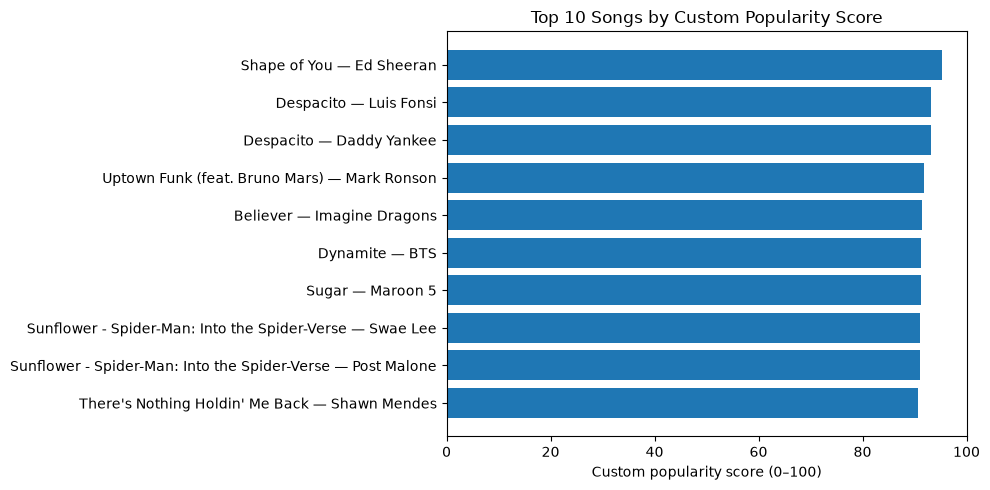

In [21]:
top10 = df.orderBy(F.desc("popularity_score")).select(
    "artist", "track", "popularity_score"
).limit(10).toPandas()

top10["label"] = top10["track"].astype(str) + " — " + top10["artist"].astype(str)
plt.figure(figsize=(10, 5))
plt.barh(top10["label"][::-1], top10["popularity_score"][::-1])
plt.xlabel("Custom popularity score (0–100)")
plt.title("Top 10 Songs by Custom Popularity Score")
plt.tight_layout()
plt.show()

## 14. Validation checks

Check the weights, saved score range and score-version coverage in Cassandra.

**Explanation:** Validate weights and scores stored in Cassandra.

In [22]:

# 1. Formula weights
weight_sum = sum(W_ENGAGEMENT.values()) + W_AUDIO
assert abs(weight_sum - 1.0) < 1e-9
print(f"1. Formula weights: stream 40% + views 25% + likes 10% + comments 5% + "
      f"audio 20% = {weight_sum:.0%}  -> OK")

# 2.-4. Re-read persisted scores + versions straight from Cassandra
v_rows = list(session.execute(
    f"SELECT popularity_score, score_version FROM {TABLE}"))
v_scores = [r.popularity_score for r in v_rows if r.popularity_score is not None]
v_total, v_pop = len(v_rows), len(v_scores)
print(f"2. Cassandra rows={v_total} populated={v_pop} missing={v_total - v_pop}")
if v_scores:
    v_min, v_max = min(v_scores), max(v_scores)
    print(f"3. Persisted score range: min={v_min} max={v_max}")
    assert 0.0 <= v_min <= 100.0 and 0.0 <= v_max <= 100.0, "Score outside 0-100!"
    print("   -> every persisted score is within 0-100: OK")

# 5. Version coverage: proves which formula produced the stored scores
v_ver = sum(1 for r in v_rows if r.score_version == SCORE_VERSION)
print(f"5. Rows with score_version == '{SCORE_VERSION}': {v_ver}/{v_total}")
assert v_ver == v_total, "Some rows are not marked with the current score version!"

# 6./7. Population + run status
assert v_pop == v_total, "Some rows are missing a popularity_score!"
print(f"6. popularity_score fully populated: {v_pop == v_total}")
status7 = (f"SKIPPED (all rows at {SCORE_VERSION})" if not CALCULATE_SCORE
           else "EXECUTED")
print(f"7. Score calculation on this run: {status7}")


1. Formula weights: stream 40% + views 25% + likes 10% + comments 5% + audio 20% = 100%  -> OK


2. Cassandra rows=19170 populated=19170 missing=0
3. Persisted score range: min=12.45 max=95.24
   -> every persisted score is within 0-100: OK
5. Rows with score_version == 'v2_audio_engagement': 19170/19170
6. popularity_score fully populated: True
7. Score calculation on this run: SKIPPED (all rows at v2_audio_engagement)


## 15. Close connections

Run this last, after all analysis, model training and plots are complete.

**Explanation:** Close connections after all work is finished.

In [23]:
# Run this only after all analyses, model saving and visualizations are complete.
try:
    session.shutdown()
except Exception:
    pass
try:
    cluster.shutdown()
except Exception:
    pass
spark.stop()
print("Cassandra and Spark connections closed.")


Cassandra and Spark connections closed.


## Summary

- Custom popularity score: streams 40%, views 25%, likes 10%, comments 5%, audio 20%.
- Cassandra score updates are versioned and use the full primary key.
- MLlib compares three regressors using audio features and `log1p(stream)`.
- Artist rankings, similar-song and preference-based recommendations are included.
- Precision@K requires independent relevance labels.
- Matplotlib is used for the top-10 chart; the interactive dashboard is separate.